# Replicating Table 2 of Bayer & Diaconis (1992): Jordan's "Premo" card trick

From *Trailing the Dovetail Shuffle to its Lair*, p. 298. The Monte Carlo procedure for each trial:

1. Start with a deck $1,\dots,n$ ($n=52$) in order.
2. Riffle shuffle it $m$ times under the **Gilbert–Shannon–Reeds (GSR)** model.
3. **Cut** the deck uniformly at random.
4. Take the **top card** and insert it at a **binomially distributed** position.
5. **Cut** the deck uniformly at random again.
6. Score every card. Let $\sigma(i)$ be the position of card $i$ and let $d(i,j)$ be the least positive integer with
   $d(i,j)\equiv\sigma(j)-\sigma(i)\pmod n$. Card $i$ gets the count
   $$\text{count}(i)=d(i-1,i)+d(i,i+1)-1$$
   with card labels taken cyclically, so card $0$ comes before card $1$.
7. With $k$ guesses, pick the $k$ cards with the highest counts, breaking ties at random. The trial succeeds if the moved card is among them.

Table 2 reports the success probability, in thousandths, for $m=2,\dots,12$ and $k=1,2,3,13,26$.

In [ ]:
import time
import math
import numpy as np
import pandas as pd

N_CARDS  = 52
N_TRIALS = 1_000_000          # the paper uses 1,000,000 trials per entry
BATCH    = 50_000             # trials processed at once (memory ~ BATCH * 52 * 8 bytes per array)
M_VALUES = list(range(2, 13)) # number of riffle shuffles
K_VALUES = [1, 2, 3, 13, 26]  # number of guesses allowed
SEED     = 1992

rng = np.random.default_rng(SEED)

## Deck operations (vectorized over a batch of decks)

A deck is a row `deck[t, p]` = the card at position `p` in trial `t`. Every operation builds a source-index array `src` and gathers `deck[t, src[t, p]]`.

**GSR riffle.** Draw an independent fair bit for each *output* position. Positions with bit 0 take the top packet in order, and positions with bit 1 take the bottom packet in order. The top packet's size is then Binomial$(n,1/2)$, and given that size every interleaving is equally likely. That is exactly the GSR model.

In [2]:
def gather(deck, src):
    return np.take_along_axis(deck, src, axis=1)

def riffle_gsr(deck, rng):
    # One GSR riffle shuffle applied to every row of deck.
    B, n = deck.shape
    bits = rng.random((B, n)) < 0.5                 # True -> card comes from bottom packet
    k = n - bits.sum(axis=1, keepdims=True)         # size of top packet ~ Bin(n, 1/2)
    rank_top = np.cumsum(~bits, axis=1) - 1         # rank among top-packet slots
    rank_bot = np.cumsum(bits, axis=1) - 1          # rank among bottom-packet slots
    src = np.where(bits, k + rank_bot, rank_top)
    return gather(deck, src)

def cut_uniform(deck, rng):
    # Cut each deck at a uniformly random point (cyclic rotation).
    B, n = deck.shape
    r = rng.integers(0, n, size=(B, 1))
    src = (np.arange(n)[None, :] + r) % n
    return gather(deck, src)

def move_top_card(deck, rng):
    # Remove the top card and reinsert it at position p ~ Binomial(n-1, 1/2) (0 = back on top).
    B, n = deck.shape
    p = rng.binomial(n - 1, 0.5, size=(B, 1))
    j = np.arange(n)[None, :]
    src = np.where(j < p, j + 1, np.where(j == p, 0, j))
    return gather(deck, src), deck[:, 0].copy()

## Scoring and success probability

`count(i) = d(i-1,i) + d(i,i+1) - 1`, with $d(i,j) = ((\sigma(j)-\sigma(i)-1) \bmod n) + 1 \in \{1,\dots,n\}$.

Ties are broken at random. Instead of sampling the tie-break, we use its exact conditional success probability. Let $G$ be the number of cards with a strictly higher count than the moved card, and $T$ the number of other cards tied with it. With $k$ guesses the success probability is
$$P(\text{success}\mid G,T)=\text{clip}\!\left(\frac{k-G}{T+1},\,0,\,1\right).$$
Its mean equals random tie-breaking, with slightly lower variance.

In [3]:
def counts(deck):
    # Count for each card label (columns indexed by card, not position).
    B, n = deck.shape
    sigma = np.empty_like(deck)
    np.put_along_axis(sigma, deck, np.broadcast_to(np.arange(n), (B, n)), axis=1)  # sigma[t, card] = position
    nxt = np.roll(sigma, -1, axis=1)   # sigma(i+1)
    prv = np.roll(sigma,  1, axis=1)   # sigma(i-1)
    d_prev = (sigma - prv - 1) % n + 1 # d(i-1, i)
    d_next = (nxt - sigma - 1) % n + 1 # d(i, i+1)
    return d_prev + d_next - 1

def success_prob(cnt, moved, k_values):
    # Expected success for each k, with uniform random tie-breaking.
    c_moved = np.take_along_axis(cnt, moved[:, None], axis=1)
    G = (cnt > c_moved).sum(axis=1)
    T = (cnt == c_moved).sum(axis=1) - 1
    return {k: np.clip((k - G) / (T + 1), 0.0, 1.0) for k in k_values}

## Main simulation

Shuffles accumulate, so each batch is shuffled once up to $m=12$. After each shuffle count $m\ge2$, the cut/move/cut/score steps run on a copy. Entries in the same batch therefore share their first shuffles across $m$, but each $(m,k)$ entry is still an unbiased estimate from `N_TRIALS` trials.

In [5]:
def simulate(n_trials=N_TRIALS, batch=BATCH, n=N_CARDS, m_values=M_VALUES,
             k_values=K_VALUES, rng=rng):
    sums = {(m, k): 0.0 for m in m_values for k in k_values}
    sums.update({("inf", k): 0.0 for k in k_values})
    done = 0
    t0 = time.time()
    while done < n_trials:
        b = min(batch, n_trials - done)
        deck = np.broadcast_to(np.arange(n, dtype=np.int64), (b, n)).copy()
        for m in range(1, max(m_values) + 1):
            deck = riffle_gsr(deck, rng)
            if m in m_values:
                for k, p in trial_from_deck(deck, rng).items():
                    sums[(m, k)] += p.sum()
        # m = infinity: perfectly random deck
        for k, p in trial_from_deck(rng.permuted(deck, axis=1), rng).items():
            sums[("inf", k)] += p.sum()
        done += b
        print(f"\r{done:,}/{n_trials:,} trials  ({time.time() - t0:.0f}s)", end="")
    print()
    cols = list(m_values) + ["inf"]
    return pd.DataFrame({c: [sums[(c, k)] / n_trials for k in k_values] for c in cols},
                        index=pd.Index(k_values, name="k guesses"))

sim = simulate()

1,000,000/1,000,000 trials  (67s)


## Results (in thousandths, like the paper)

In [6]:
paper = pd.DataFrame(
    [[997, 839, 288,  88,  42,  28,  23,  21,  20,  20,  19,  19],
     [1000, 943, 471, 168,  83,  57,  47,  42,  40,  39,  39,  38],
     [1000, 965, 590, 238, 123,  85,  70,  63,  61,  59,  58,  58],
     [1000, 998, 884, 617, 427, 334, 290, 270, 260, 254, 252, 250],
     [1000, 999, 975, 835, 688, 596, 548, 524, 513, 505, 503, 500]],
    index=pd.Index(K_VALUES, name="k guesses"), columns=M_VALUES + ["inf"])

ours = (sim * 1000).round().astype(int)
print("Simulated (m = number of shuffles):")
display(ours)
print("Bayer & Diaconis (1992), Table 2:")
display(paper)
print("Difference (simulated - paper):")
display(ours - paper)

Simulated (m = number of shuffles):


,2,3,4,5,6,7,8,9,10,11,12,inf
k guesses,,,,,,,,,,,,
1,997,840,290,88,42,29,24,21,20,20,19,19
2,1000,944,472,168,83,57,47,42,40,39,39,38
3,1000,965,591,239,123,85,71,64,61,59,58,58
13,1000,998,884,618,427,334,291,269,260,255,253,250
26,1000,999,975,835,687,596,549,524,513,506,502,499


Bayer & Diaconis (1992), Table 2:


,2,3,4,5,6,7,8,9,10,11,12,inf
k guesses,,,,,,,,,,,,
1,997,839,288,88,42,28,23,21,20,20,19,19
2,1000,943,471,168,83,57,47,42,40,39,39,38
3,1000,965,590,238,123,85,70,63,61,59,58,58
13,1000,998,884,617,427,334,290,270,260,254,252,250
26,1000,999,975,835,688,596,548,524,513,505,503,500


Difference (simulated - paper):


,2,3,4,5,6,7,8,9,10,11,12,inf
k guesses,,,,,,,,,,,,
1,0,1,2,0,0,1,1,0,0,0,0,0
2,0,1,1,0,0,0,0,0,0,0,0,0
3,0,0,1,1,0,0,1,1,0,0,0,0
13,0,0,0,1,0,0,1,-1,0,1,1,0
26,0,0,0,0,-1,0,1,0,0,1,-1,-1


The Monte Carlo standard error per entry is at most $\sqrt{0.25/10^6}\approx0.0005$, i.e. about 0.5 in thousandths, so differences of ±1–2 are noise.

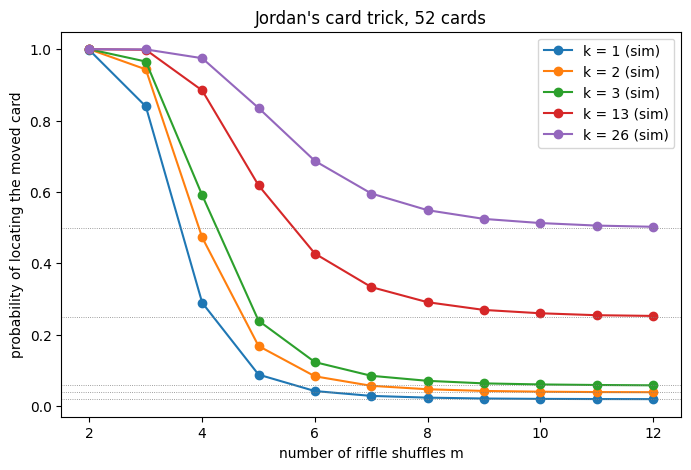

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for k in K_VALUES:
    ax.plot(M_VALUES, sim.loc[k, M_VALUES], "o-", label=f"k = {k} (sim)")
    ax.axhline(k / N_CARDS, color="gray", lw=0.6, ls=":")
ax.set_xlabel("number of riffle shuffles m")
ax.set_ylabel("probability of locating the moved card")
ax.set_title("Jordan's card trick, 52 cards")
ax.legend()
plt.show()

### Advantage over random guessing

The paper notes that, in the limit, the advantage over guessing ($p - k/52$) halves with each extra shuffle. The ratio of successive advantages should approach 0.5.

In [8]:
# beyond m ~ 9 the advantage is ~1e-3, comparable to Monte Carlo noise, so ratios become meaningless
ms = [m for m in M_VALUES if m <= 9]
adv = sim[ms].sub(sim["inf"], axis=0)
ratio = pd.DataFrame(adv.iloc[:, 1:].values / adv.iloc[:, :-1].values,
                     index=adv.index, columns=[f"{m}/{m-1}" for m in ms[1:]])
display(ratio.round(2))

,3/2,4/3,5/4,6/5,7/6,8/7,9/8
k guesses,,,,,,,
1,0.84,0.33,0.25,0.33,0.41,0.48,0.44
2,0.94,0.48,0.30,0.35,0.41,0.47,0.45
3,0.96,0.59,0.34,0.36,0.42,0.48,0.46
13,1.00,0.85,0.58,0.48,0.47,0.49,0.47
26,1.00,0.95,0.71,0.56,0.51,0.52,0.51
